# TakeMeter — training notebook

This notebook trains your classifier. It runs **on your own machine**, from
inside your project folder — no accounts, no upload, nothing to connect.

**Before you run anything:**

1. **Open it from your repo**, not from a copy somewhere else. Everything it
   writes lands next to your code so you can commit it normally.
2. **Activate your virtual environment first.** In VS Code, that's the kernel
   picker in the top right — choose the `.venv` inside this project. Getting
   this wrong is the single most common way the first cell fails.

How long it takes depends on what you're running on. Section 1 tells you, and
the first cell of section 4 prints a time as it goes. On a laptop CPU expect a
few minutes per seed; on a GPU, well under one.

---

### What's here

| Section | When | What it does |
|---|---|---|
| **1. Setup** | unit 5 | Checks what you're running on and where |
| **2. Your labels** | unit 5 | Your label map, and reading `labels.csv` |
| **3. Split** | unit 5 | 70/15/15, with the seed as an editable constant |
| **4. Train** | unit 5 | The training run |
| **5. Results** | unit 5 | Writes `results.json` and `test_split.csv` |
| **6. Three seeds** | unit 6 | The same thing three times, on three splits |
| **7. Confusion matrix** | unit 6 | Which labels get mixed up, as a table |

## 1. Setup

Two cells. Run them once at the start of a session.

The first tells you what hardware you're training on and records it, because
**that is part of your result**. The second confirms the notebook can see your
project files.

In [2]:
# Everything this notebook needs is already in requirements.txt — you installed
# it when you set the project up. This cell just says what you're running on.

import torch


def pick_device():
    """
    Where training will run. Fastest first.

    `cuda`  an NVIDIA GPU.
    `mps`   Apple Silicon's GPU — M1 and later. Much faster than the CPU path.
    `cpu`   everything else. Slower, and it works: this dataset is small enough
            that a full three-seed run is minutes, not hours.
    """
    if torch.cuda.is_available():
        return "cuda", torch.cuda.get_device_name(0)
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        return "mps", "Apple Silicon GPU (MPS)"
    return "cpu", "CPU"


DEVICE, DEVICE_NAME = pick_device()

print(f"device: {DEVICE}  ({DEVICE_NAME})")
print(f"torch:  {torch.__version__}")
print()
print("⚠️  WRITE THIS DOWN. Your results depend on it.")
print()
print("Two people running this notebook on the same data with the same seed can")
print("get different numbers, because different hardware does the arithmetic in")
print("a slightly different order. That is not a bug and it is not one of you")
print("being wrong — it is a real property of the thing you are building, and")
print("unit 6 asks you to report it alongside your three seeds.")

device: mps  (Apple Silicon GPU (MPS))
torch:  2.14.1

⚠️  WRITE THIS DOWN. Your results depend on it.

Two people running this notebook on the same data with the same seed can
get different numbers, because different hardware does the arithmetic in
a slightly different order. That is not a bug and it is not one of you
being wrong — it is a real property of the thing you are building, and
unit 6 asks you to report it alongside your three seeds.


### Where you are

Nothing to connect and nothing to clone — this notebook runs inside your own
repo, so `labels.csv` is simply *there* and anything written lands beside it.

**Fill in the two lines.** They only label your results; nothing here talks to
GitHub. You commit what this notebook writes the same way you commit anything
else.

In [3]:
# ── FILL THIS IN ─────────────────────────────────────────────────────────────

NAME  = "Your Name"          # only used to label your results
EMAIL = "you@example.com"    # same — nothing here talks to GitHub

# ─────────────────────────────────────────────────────────────────────────────
import os
from pathlib import Path

# This notebook runs from inside your own repo, so there is nothing to clone
# and nothing to authenticate. Everything it writes lands next to your code and
# you commit it the same way you commit anything else.
REPO_DIR = Path.cwd()

expected = ["labels.csv", "criteria.md", "baseline.py"]
missing = [f for f in expected if not (REPO_DIR / f).exists()]

if missing and (REPO_DIR / "takemeter.ipynb").exists():
    print(f"Working in: {REPO_DIR}")
    print(f"[note] not found yet: {', '.join(missing)}")
    print("       labels.csv is Milestone 4 — that's expected before then.")
elif missing:
    print("This notebook expects to be run from inside your project folder.")
    print(f"It is currently running in: {REPO_DIR}")
    print("Open the notebook from the repo you cloned, not from a copy.")
else:
    print(f"Working in: {REPO_DIR}")
    print(f"Results will be labelled: {NAME} <{EMAIL}>")
    for f in sorted(os.listdir(REPO_DIR)):
        if not f.startswith("."):
            print(f"  {f}")

Working in: /Users/camila/ai201-project3-takemeter-starter-v2026
[note] not found yet: labels.csv
       labels.csv is Milestone 4 — that's expected before then.


## 2. Your labels

Two things to fill in. Everything after this is automatic.

**`LABELS` must match your CSV exactly** — including capitals and spaces. A
label in your file that isn't in this list is the single most common reason
this notebook fails.

In [4]:
# ── FILL THIS IN ─────────────────────────────────────────────────────────────

# Your labels, exactly as they appear in the `label` column of your CSV.
LABELS = ["template", "book_centered", "personal", "bare_ask"]

# The model you're fine-tuning. Leave this unless you have a reason.
BASE_MODEL = "distilbert-base-uncased"

# ── Training settings ────────────────────────────────────────────────────────
# These are the defaults. Hyperparameters are vocabulary this unit, not
# decisions — if you change one, write down what and why in your README.

EPOCHS = 3
LEARNING_RATE = 2e-5
BATCH_SIZE = 16

# How many tokens of each post the model reads. Anything longer is truncated,
# anything shorter is padded up to it — so this is really "how much work per
# post", and it costs time and memory whether your posts are that long or not.
#
# 128 covers almost every post in a corpus like this. Raising it to 256 roughly
# doubles both the time and the memory for text most people don't have.
MAX_LENGTH = 128

# ── The seed ─────────────────────────────────────────────────────────────────
# This fixes which posts land in which split. Change it and you get a different
# split and different numbers.
#
# ⚠️ NEXT UNIT YOU CHANGE THIS THREE TIMES. That's not busywork — it's how you
# find out whether your number is real or whether you got a friendly draw.

SEED = 42

print(f"{len(LABELS)} labels: {', '.join(LABELS)}")
print(f"seed {SEED}, {EPOCHS} epochs, lr {LEARNING_RATE}, batch {BATCH_SIZE}")

4 labels: template, book_centered, personal, bare_ask
seed 42, 3 epochs, lr 2e-05, batch 16


### Your data

`labels.csv` came down with the clone, so there's nothing to upload. If you've
just added rows on your laptop, commit and push them there first, then re-run
the connect cell.

Don't split the file yourself — the next section does that, and doing it twice
is how examples leak between training and test.

No data of your own yet? Point `CSV` at `data/practice_labels.csv`, the 60-post
set used in class.

In [5]:
import pandas as pd

CSV = "data/labels.csv"              # "data/practice_labels.csv" to practise

df = pd.read_csv(CSV)

print(f"Loaded {CSV}: {len(df)} rows")
print(f"Columns: {', '.join(df.columns)}")

Loaded data/labels.csv: 200 rows
Columns: text, label, note


### Check it before you train

This catches the problems that would otherwise show up as a confusing error
forty minutes from now — or, worse, as a model that trained on bad data and
told you nothing was wrong.

In [6]:
def check_dataset(df, labels):
    """
    Look for the things that break a training run or quietly ruin it.

    Returns (problems, warnings). Problems stop you; warnings are worth reading.
    """
    problems, warnings = [], []

    for column in ("text", "label"):
        if column not in df.columns:
            problems.append(f"No '{column}' column. Found: {', '.join(df.columns)}")
    if problems:
        return problems, warnings

    blank = df["text"].isna().sum() + (df["text"].astype(str).str.strip() == "").sum()
    if blank:
        problems.append(f"{blank} rows have an empty text column.")

    found = set(df["label"].dropna().astype(str).str.strip().unique())
    expected = set(labels)

    unknown = found - expected
    if unknown:
        problems.append(
            f"Labels in your CSV that aren't in LABELS: {sorted(unknown)}. "
            f"Check capitals and spaces — 'Hot_take' and 'hot_take' are different."
        )

    unused = expected - found
    if unused:
        warnings.append(f"Labels in LABELS that never appear in your CSV: {sorted(unused)}")

    counts = df["label"].value_counts()
    total = len(df)
    for label, count in counts.items():
        share = count / total
        if share > 0.70:
            problems.append(
                f"'{label}' is {share:.0%} of your data. The brief caps this at 70% — "
                f"above that the model learns to guess it. Collect more of the thin labels."
            )
        elif share > 0.60:
            warnings.append(f"'{label}' is {share:.0%} of your data. Getting lopsided.")

    if total < 150:
        warnings.append(
            f"{total} rows. The brief's floor for a submission is 150 and it asks "
            f"for 200. Training will still run — this is fine for the practice "
            f"data, and something to fix before you submit."
        )
    elif total < 200:
        warnings.append(f"{total} rows — under the 200 the brief asks for. Say so in your README.")

    duplicates = df["text"].duplicated().sum()
    if duplicates:
        warnings.append(
            f"{duplicates} duplicate posts. They'll land in different splits and "
            f"inflate your score — that's leakage."
        )

    for label, count in counts.items():
        if count < 20:
            warnings.append(
                f"Only {count} examples of '{label}'. Its test split will be tiny, "
                f"so its F1 will jump around between seeds."
            )

    return problems, warnings


problems, warnings = check_dataset(df, LABELS)

for w in warnings:
    print(f"[look at]  {w}")
for p in problems:
    print(f"[FIX ME]   {p}")

if not problems:
    print("\nData looks fine.")
    print()
    print(df["label"].value_counts().to_string())
else:
    print("\nFix the [FIX ME] lines before training.")


Data looks fine.

label
book_centered    95
template         44
personal         31
bare_ask         30


## 3. Split

70% train, 15% validation, 15% test.

The split is **stratified** — each split gets roughly the same label proportions
as the whole file. Without that, a small label can end up with nothing in the
test set and its F1 becomes undefined.

**Lock the test set and don't look at it again until evaluation.** Checking how
you're doing against the test set and then changing things is the slow-motion
version of training on it.

In [7]:
from sklearn.model_selection import train_test_split


def split_dataset(df, seed, test_size=0.15, val_size=0.15):
    """
    Stratified 70/15/15. Returns (train, val, test) DataFrames.

    Stratifying falls back to a plain random split if any label is too rare to
    stratify on — that's a warning sign about the dataset, not about the split.
    """
    def _stratify_on(frame):
        counts = frame["label"].value_counts()
        return frame["label"] if counts.min() >= 2 else None

    rest, test = train_test_split(
        df, test_size=test_size, random_state=seed, stratify=_stratify_on(df)
    )
    val_share = val_size / (1 - test_size)
    train, val = train_test_split(
        rest, test_size=val_share, random_state=seed, stratify=_stratify_on(rest)
    )
    return (
        train.reset_index(drop=True),
        val.reset_index(drop=True),
        test.reset_index(drop=True),
    )


def describe_splits(train, val, test, labels):
    """A table of per-label counts per split, and a note on the thin ones."""
    import pandas as pd

    table = pd.DataFrame({
        "train": train["label"].value_counts(),
        "val": val["label"].value_counts(),
        "test": test["label"].value_counts(),
    }).reindex(labels).fillna(0).astype(int)

    thin = [label for label in labels if table.loc[label, "test"] < 8]
    return table, thin


train_df, val_df, test_df = split_dataset(df, SEED)
table, thin = describe_splits(train_df, val_df, test_df, LABELS)

print(f"train {len(train_df)}  ·  val {len(val_df)}  ·  test {len(test_df)}\n")
print(table.to_string())

if thin:
    print()
    for label in thin:
        n = table.loc[label, "test"]
        print(f"[note] '{label}' has only {n} examples in the test split.")
    print()
    print("A metric computed on that few examples moves a lot between seeds.")
    print("Write that down now — next unit it's a diagnosis, not a surprise.")

train 139  ·  val 31  ·  test 30

               train  val  test
label                          
template          30    7     7
book_centered     66   15    14
personal          22    4     5
bare_ask          21    5     4

[note] 'template' has only 7 examples in the test split.
[note] 'personal' has only 5 examples in the test split.
[note] 'bare_ask' has only 4 examples in the test split.

A metric computed on that few examples moves a lot between seeds.
Write that down now — next unit it's a diagnosis, not a surprise.


## 4. Train

About ten minutes on a T4. It'll print a loss for each epoch as it goes.

**The loss curve tells you training is converging — not that the model learned
what you meant.** A model can drive loss down by memorising or by latching onto
something spurious, and neither is visible here. That's what next unit is for.

In [8]:
import numpy as np
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, set_seed,
)
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support


def to_ids(df, labels):
    """Map label strings to the integer ids the model wants."""
    lookup = {label: i for i, label in enumerate(labels)}
    out = df.copy()
    out["labels"] = out["label"].astype(str).str.strip().map(lookup)
    return out[["text", "labels"]]


def compute_metrics(eval_pred):
    logits, gold = eval_pred
    predicted = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(gold, predicted),
        "f1_macro": f1_score(gold, predicted, average="macro", zero_division=0),
    }


def train_model(train_df, val_df, labels, seed, epochs, learning_rate, batch_size,
                base_model, run_name="run", quiet=False):
    """Fine-tune and return (trainer, tokenizer)."""
    set_seed(seed)

    tokenizer = AutoTokenizer.from_pretrained(base_model)
    model = AutoModelForSequenceClassification.from_pretrained(
        base_model,
        num_labels=len(labels),
        id2label={i: l for i, l in enumerate(labels)},
        label2id={l: i for i, l in enumerate(labels)},
    )

    def tokenize(batch):
        return tokenizer(batch["text"], truncation=True, padding="max_length", max_length=MAX_LENGTH)

    train_ds = Dataset.from_pandas(to_ids(train_df, labels)).map(tokenize, batched=True)
    val_ds = Dataset.from_pandas(to_ids(val_df, labels)).map(tokenize, batched=True)

    args = TrainingArguments(
        output_dir="./takemeter_out",
        num_train_epochs=epochs,
        learning_rate=learning_rate,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        eval_strategy="epoch",
        save_strategy="no",
        logging_steps=10,
        seed=seed,
        report_to="none",
        disable_tqdm=quiet,
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        compute_metrics=compute_metrics,
    )
    trainer.train()
    return trainer, tokenizer

#  -------------- Modifying since I am compating two Training settings --------------
# trainer, tokenizer = train_model(
#     train_df, val_df, LABELS, SEED, EPOCHS, LEARNING_RATE, BATCH_SIZE, BASE_MODEL
# )
# print("\nTrained.")

/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### TRAINING: Run A and B -  different hyperparameter: epochs

In [9]:
def run_experiment(name, seed, epochs, learning_rate, batch_size, base_model):
    """Train with the given params; return trainer, tokenizer and a results dict."""
    trainer, tokenizer = train_model(
        train_df, val_df, LABELS, run_name=name,
        seed= seed,
        epochs=epochs,
        learning_rate=learning_rate,
        batch_size=batch_size,
        base_model=base_model,
    )
    history = trainer.state.log_history
    results = {
        "name": name,
        "seed": seed, 
        "epochs": epochs, 
        "learning_rate": learning_rate, 
        "batch_size": batch_size, 
        "base_model": base_model,
        "train_loss": [(h["step"], h["loss"]) for h in history if "loss" in h],
        "eval_history": [h for h in history if "eval_loss" in h],
        "final_eval": trainer.evaluate(),   # metrics on val set for the final model
    }
    return trainer, tokenizer, results


# ---- Run A: original parameters ----
trainer_a, tokenizer_a, res_a = run_experiment(
    "A_baseline",
    seed=SEED, 
    epochs=EPOCHS, 
    learning_rate=LEARNING_RATE,
    batch_size=BATCH_SIZE, 
    base_model=BASE_MODEL,
)
print("\nRun A trained.")


# ---- Run B: experimental parameters ----
trainer_b, tokenizer_b, res_b = run_experiment(
    "B_experiment",
    seed=SEED,                 # same
    epochs=EPOCHS + 2,         # Training for longer to compare accuracy and changes in model
    learning_rate=2e-5,        # same
    batch_size=BATCH_SIZE,
    base_model=BASE_MODEL,
)
print("\nRun B trained.")

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Map: 100%|██████████| 31/31 [00:00<00:00, 7930.19 examples/s]
/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,No log,1.175866,0.645161,0.391260
2,1.313600,1.005572,0.709677,0.442308
3,1.073300,0.956947,0.709677,0.442308


/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)



Run A trained.


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Map: 100%|██████████| 31/31 [00:00<00:00, 8580.14 examples/s]
/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,No log,1.158433,0.645161,0.391260
2,1.309600,0.952655,0.709677,0.442308
3,1.036300,0.853967,0.709677,0.442308
4,0.941500,0.808542,0.709677,0.442308
5,0.830000,0.791918,0.709677,0.442308


/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS 


Run B trained.


#### Comparing Both Trainings

,epochs,learning_rate,batch_size,seed,eval_loss,accuracy,f1_macro
run,,,,,,,
A_baseline,3,0.0,16,42,0.9569,0.7097,0.4423
B_experiment,5,0.0,16,42,0.7919,0.7097,0.4423


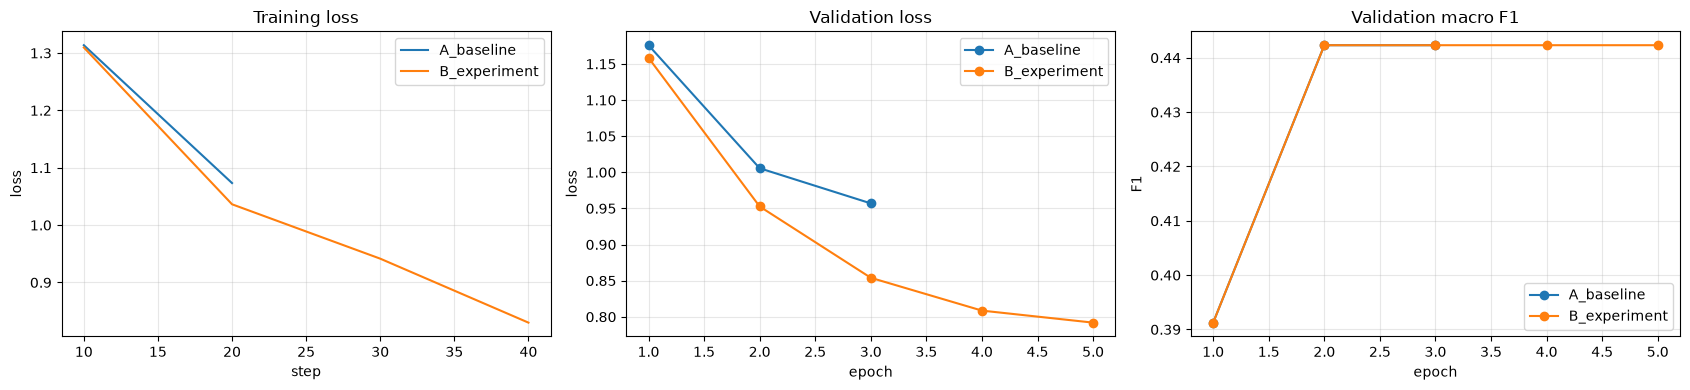

In [10]:
import matplotlib.pyplot as plt

runs = [res_a, res_b]

# --- Metrics table ---
rows = []
for r in runs:
    fe = r["final_eval"]
    rows.append({
        "run": r["name"],
        "epochs": r["epochs"],
        "learning_rate": r["learning_rate"],
        "batch_size": r["batch_size"],
        "seed": r["seed"],
        "eval_loss": fe["eval_loss"],
        "accuracy": fe["eval_accuracy"],
        "f1_macro": fe["eval_f1_macro"],
    })
comparison = pd.DataFrame(rows).set_index("run")
display(comparison.round(4))

# --- Loss and metric curves (unchanged) ---
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

for r in runs:
    if r["train_loss"]:
        steps, losses = zip(*r["train_loss"])
        axes[0].plot(steps, losses, label=r["name"])
    eh = r["eval_history"]
    axes[1].plot([h["epoch"] for h in eh], [h["eval_loss"] for h in eh], marker="o", label=r["name"])
    axes[2].plot([h["epoch"] for h in eh], [h["eval_f1_macro"] for h in eh], marker="o", label=r["name"])

axes[0].set(title="Training loss", xlabel="step", ylabel="loss")
axes[1].set(title="Validation loss", xlabel="epoch", ylabel="loss")
axes[2].set(title="Validation macro F1", xlabel="epoch", ylabel="F1")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Results

Runs the model on the test split — the one it has never seen — and writes
`results.json`.

`results.json` records **how sure the model was**, whether its confident
guesses were right more often than its unsure ones. If one of your criteria is
about confidence, that's the number that tests it. It also records **the device
you trained on**, which you'll want next unit when your numbers and someone
else's don't match.

It also writes `test_split.csv`, the held-out posts themselves. Next unit
`baseline.py` reads that file so the baseline is scored on exactly these posts
and not a different sample. Two numbers from two different sets of posts aren't
a comparison.

**Commit both files.** Don't read the numbers closely yet — your criteria are
already filed, and reading results before you've written your standard is how
the standard quietly moves.

In [11]:
import json


def evaluate(trainer, tokenizer, test_df, labels, seed=None):
    """Score the model on the held-out split. Returns a plain dict."""
    from datasets import Dataset

    def tokenize(batch):
        return tokenizer(batch["text"], truncation=True, padding="max_length", max_length=MAX_LENGTH)

    test_ds = Dataset.from_pandas(to_ids(test_df, labels)).map(tokenize, batched=True)
    output = trainer.predict(test_ds)

    predicted = np.argmax(output.predictions, axis=-1)
    gold = np.array(output.label_ids)

    # How sure the model was about each guess. Softmax over the raw scores, then
    # the winning one. A criterion about confidence can't be tested without it.
    scores = output.predictions
    exp = np.exp(scores - scores.max(axis=-1, keepdims=True))
    confidence = (exp / exp.sum(axis=-1, keepdims=True)).max(axis=-1)

    precision, recall, f1, support = precision_recall_fscore_support(
        gold, predicted, labels=list(range(len(labels))), zero_division=0
    )

    return {
        "seed": seed,
        "n_test": int(len(gold)),
        "accuracy": float(accuracy_score(gold, predicted)),
        "f1_macro": float(f1_score(gold, predicted, average="macro", zero_division=0)),
        "per_label": {
            label: {
                "precision": float(precision[i]),
                "recall": float(recall[i]),
                "f1": float(f1[i]),
                "support": int(support[i]),
            }
            for i, label in enumerate(labels)
        },
        "confusion": confusion_counts(gold, predicted, labels),
        "confidence": confidence_report(confidence, gold, predicted),
    }


def confidence_report(confidence, gold, predicted):
    """
    Are the model's confident guesses right more often than its unsure ones?

    If you wrote a criterion about confidence, this is what tests it. If the
    two thirds score about the same, the model's confidence means nothing —
    which is itself worth writing down.
    """
    right = gold == predicted
    ranked = np.argsort(confidence)
    third = max(1, len(confidence) // 3)
    least, most = ranked[:third], ranked[-third:]

    return {
        "mean_when_right": float(confidence[right].mean()) if right.any() else None,
        "mean_when_wrong": float(confidence[~right].mean()) if (~right).any() else None,
        "accuracy_most_confident_third": float(right[most].mean()),
        "accuracy_least_confident_third": float(right[least].mean()),
        "n_per_third": int(third),
    }


def confusion_counts(gold, predicted, labels):
    """Rows are true labels, columns are guesses. Plain nested dict."""
    matrix = {t: {p: 0 for p in labels} for t in labels}
    for g, p in zip(gold, predicted):
        matrix[labels[int(g)]][labels[int(p)]] += 1
    return matrix


def evaluate_and_save(name, trainer, tokenizer, params):
    """Score one run on the test split and write results_<name>.json."""
    results = evaluate(trainer, tokenizer, test_df, LABELS, seed=params["seed"])

    results["run"] = name
    results["epochs"] = params["epochs"]
    results["learning_rate"] = params["learning_rate"]
    results["batch_size"] = params["batch_size"]
    results["base_model"] = params["base_model"]
    results["device"] = DEVICE
    results["device_name"] = DEVICE_NAME
    results["torch_version"] = torch.__version__
    results["max_length"] = MAX_LENGTH

    with open(f"results_{name}.json", "w") as f:
        json.dump(results, f, indent=2)

    print(f"=== {name} ===")
    print(f"accuracy  {results['accuracy']:.3f}")
    print(f"macro F1  {results['f1_macro']:.3f}\n")
    for label, scores in results["per_label"].items():
        print(f"  {label:<16} F1 {scores['f1']:.3f}   (n={scores['support']})")
    c = results["confidence"]
    print(f"\nconfidence   most-sure third {c['accuracy_most_confident_third']:.3f}"
          f"   ·   least-sure third {c['accuracy_least_confident_third']:.3f}\n")
    return results


test_a = evaluate_and_save("A_baseline", trainer_a, tokenizer_a, res_a)
test_b = evaluate_and_save("B_experiment", trainer_b, tokenizer_b, res_b)

# The test split is the same for both runs, so it is written once.
test_df.to_csv("test_split.csv", index=False)

print("Wrote results_A_baseline.json, results_B_experiment.json and test_split.csv.")
print("Commit them all — they're the evidence the runs happened, and next unit")
print("reads test_split.csv.")


Map: 100%|██████████| 30/30 [00:00<00:00, 1100.79 examples/s]
/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


=== A_baseline ===
accuracy  0.667
macro F1  0.414

  template         F1 0.933   (n=7)
  book_centered    F1 0.722   (n=14)
  personal         F1 0.000   (n=4)
  bare_ask         F1 0.000   (n=5)

confidence   most-sure third 0.900   ·   least-sure third 0.500



Map: 100%|██████████| 30/30 [00:00<00:00, 7112.61 examples/s]
/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


=== B_experiment ===
accuracy  0.667
macro F1  0.414

  template         F1 0.933   (n=7)
  book_centered    F1 0.722   (n=14)
  personal         F1 0.000   (n=4)
  bare_ask         F1 0.000   (n=5)

confidence   most-sure third 0.900   ·   least-sure third 0.300

Wrote results_A_baseline.json, results_B_experiment.json and test_split.csv.
Commit them all — they're the evidence the runs happened, and next unit
reads test_split.csv.


---
---

# ⬇️ Unit 6 starts here

Nothing below this line is needed in unit 5. Come back next unit.

---

## 6. Three seeds

Your score depends on which posts landed in the test split. Change the split,
change the score. So run it three times.

**This is one cell on purpose** — all three seeds run in a single execution, so
you get a comparable set or none at all. On a laptop CPU it's a few minutes per
seed; start it and go and do Milestone 3 while it runs.

If accuracy swings more than about ten points across the three, your dataset is
too small or too lopsided for a stable measure. That's a genuine diagnosis, not
a mistake.

**Set `RUN_LABEL` before each run.** `"before"` now; `"after"` when you come
back in Milestone 5. Leave it and the improvement overwrites the numbers you
are comparing it against.

In [22]:
SEEDS = [42, 7, 2024]

# WARNING: change this to "after" before you re-run this cell in Milestone 5.
#
# Without it the improvement run overwrites your before-numbers, and the file
# you committed as evidence quietly becomes the other set. Same idea as the
# --label flag on the eval scripts in units 2 and 4.
RUN_LABEL = "after"

all_results = []

for i, seed in enumerate(SEEDS, 1):
    print(f"\n{'=' * 60}\nSeed {seed}  ({i} of {len(SEEDS)})\n{'=' * 60}")

    tr, va, te = split_dataset(df, seed)
    t, tok = train_model(
        tr, va, LABELS, seed, EPOCHS, LEARNING_RATE, BATCH_SIZE, BASE_MODEL, quiet=True
    )
    r = evaluate(t, tok, te, LABELS, seed=seed)
    all_results.append(r)

    print(f"  accuracy {r['accuracy']:.3f}   macro F1 {r['f1_macro']:.3f}")

OUT = f"results_three_seeds_{RUN_LABEL}.json"

for r in all_results:
    r["device"] = DEVICE
    r["device_name"] = DEVICE_NAME
    r["torch_version"] = torch.__version__
    r["max_length"] = MAX_LENGTH

with open(OUT, "w") as f:
    json.dump(all_results, f, indent=2)

print(f"\n\n{'=' * 60}\nAll three done.\n{'=' * 60}")
print(f"Wrote {OUT}.")
if RUN_LABEL == "before":
    print('Re-running after your improvement? Set RUN_LABEL = \"after" first,')
    print('or you will overwrite the numbers you are comparing against.')

print(f"Wrote {OUT}. Commit it.")



Seed 42  (1 of 3)


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Map: 100%|██████████| 31/31 [00:00<00:00, 6281.63 examples/s]
/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'eval_loss': 1.166081428527832, 'eval_accuracy': 0.6774193548387096, 'eval_f1_macro': 0.4182692307692308, 'eval_runtime': 0.2781, 'eval_samples_per_second': 111.467, 'eval_steps_per_second': 7.191, 'epoch': 1.0}


/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'loss': 1.3121, 'grad_norm': 2.136781930923462, 'learning_rate': 1.3333333333333333e-05, 'epoch': 1.1111111111111112}
{'eval_loss': 1.006813406944275, 'eval_accuracy': 0.7096774193548387, 'eval_f1_macro': 0.4423076923076923, 'eval_runtime': 0.2574, 'eval_samples_per_second': 120.414, 'eval_steps_per_second': 7.769, 'epoch': 2.0}


...

/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'loss': 1.1158, 'grad_norm': 3.0898730754852295, 'learning_rate': 5.925925925925926e-06, 'epoch': 2.2222222222222223}
{'eval_loss': 1.0014592409133911, 'eval_accuracy': 0.7096774193548387, 'eval_f1_macro': 0.4423076923076923, 'eval_runtime': 0.2582, 'eval_samples_per_second': 120.056, 'eval_steps_per_second': 7.746, 'epoch': 3.0}
{'train_runtime': 9.9363, 'train_samples_per_second': 41.967, 'train_steps_per_second': 2.717, 'train_loss': 1.170972223635073, 'epoch': 3.0}


Map: 100%|██████████| 30/30 [00:00<00:00, 4451.13 examples/s]

  accuracy 0.667   macro F1 0.415


All three done.
Wrote results_three_seeds_after.json.
Wrote results_three_seeds_after.json. Commit it.



/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


### The numbers, as a table

Paste this into your README's run log. The Target and Verdict columns are yours
to fill in from `criteria.md` — the notebook doesn't know what you promised.

In [23]:
def spread_table(all_results, labels):
    """A markdown table of every measure across every seed."""
    seeds = [r["seed"] for r in all_results]
    header = f"| Measure | {' | '.join(f'Seed {s}' for s in seeds)} | Spread |"
    divider = "|---|" + "|".join(["---"] * (len(seeds) + 1)) + "|"
    rows = [header, divider]

    def row(name, values, fmt="{:.3f}"):
        spread = max(values) - min(values)
        cells = " | ".join(fmt.format(v) for v in values)
        return f"| {name} | {cells} | {fmt.format(spread)} |"

    rows.append(row("Overall accuracy", [r["accuracy"] for r in all_results]))
    rows.append(row("Macro F1", [r["f1_macro"] for r in all_results]))
    for label in labels:
        rows.append(row(f"F1 — `{label}`",
                        [r["per_label"][label]["f1"] for r in all_results]))
    return "\n".join(rows)


def stability_note(all_results):
    """Say plainly whether the spread makes these numbers trustworthy."""
    accuracies = [r["accuracy"] for r in all_results]
    spread = max(accuracies) - min(accuracies)
    if spread > 0.10:
        return (f"Accuracy moved {spread:.3f} across seeds — more than 10 points. "
                f"Your dataset is too small or too lopsided for a stable measure. "
                f"That IS a diagnosis. Write it down.")
    if spread > 0.05:
        return (f"Accuracy moved {spread:.3f} across seeds. Enough that a criterion "
                f"landing within that band can't really be called either way.")
    return f"Accuracy moved {spread:.3f} across seeds. Stable enough to trust."


print(spread_table(all_results, LABELS))
print()
print(stability_note(all_results))

| Measure | Seed 42 | Seed 7 | Seed 2024 | Spread |
|---|---|---|---|---|
| Overall accuracy | 0.667 | 0.700 | 0.667 | 0.033 |
| Macro F1 | 0.414 | 0.439 | 0.415 | 0.025 |
| F1 — `template` | 0.933 | 1.000 | 0.923 | 0.077 |
| F1 — `book_centered` | 0.722 | 0.757 | 0.737 | 0.035 |
| F1 — `personal` | 0.000 | 0.000 | 0.000 | 0.000 |
| F1 — `bare_ask` | 0.000 | 0.000 | 0.000 | 0.000 |

Accuracy moved 0.033 across seeds. Stable enough to trust.


## 7. Confusion matrix

Rows are true labels, columns are the model's guesses. The diagonal is right
answers; everything off it is a mistake with a direction.

**Your README needs this typed out as a markdown table.** The cell prints one
you can copy. An image of a matrix earns nothing.

Then find your biggest off-diagonal number and say what it means in one
sentence. Not "the model made mistakes" — *which* boundary it didn't learn, and
which way round.

In [24]:
def matrix_markdown(confusion, labels):
    """The confusion matrix as a markdown table, ready to paste."""
    header = f"| true \\ predicted | {' | '.join(labels)} |"
    divider = "|---|" + "|".join(["---"] * len(labels)) + "|"
    rows = [header, divider]
    for true_label in labels:
        cells = " | ".join(str(confusion[true_label][p]) for p in labels)
        rows.append(f"| **{true_label}** | {cells} |")
    return "\n".join(rows)


def biggest_confusion(confusion, labels):
    """The largest off-diagonal cell: (true, predicted, count)."""
    worst = None
    for true_label in labels:
        for predicted in labels:
            if true_label == predicted:
                continue
            count = confusion[true_label][predicted]
            if worst is None or count > worst[2]:
                worst = (true_label, predicted, count)
    return worst


confusion = all_results[0]["confusion"]

print(matrix_markdown(confusion, LABELS))
print()

true_label, predicted, count = biggest_confusion(confusion, LABELS)
reverse = confusion[predicted][true_label]

print(f"Biggest confusion: {count} real `{true_label}` posts called `{predicted}`.")
print(f"The other direction: {reverse} real `{predicted}` posts called `{true_label}`.")
print()
if count > reverse * 2 and count > 2:
    print(f"That's lopsided — the model leans toward `{predicted}` on this pair.")
    print(f"A direction like that usually points at your labelling rather than the")
    print(f"model. Your agreement report is the thing that can tell you which.")
else:
    print("Roughly symmetric — the model finds this pair hard in both directions,")
    print("which more often means the boundary itself is genuinely hard.")

| true \ predicted | template | book_centered | personal | bare_ask |
|---|---|---|---|---|
| **template** | 7 | 0 | 0 | 0 |
| **book_centered** | 1 | 13 | 0 | 0 |
| **personal** | 0 | 4 | 0 | 0 |
| **bare_ask** | 0 | 5 | 0 | 0 |

Biggest confusion: 5 real `bare_ask` posts called `book_centered`.
The other direction: 0 real `book_centered` posts called `bare_ask`.

That's lopsided — the model leans toward `book_centered` on this pair.
A direction like that usually points at your labelling rather than the
model. Your agreement report is the thing that can tell you which.


### Improvement: Class-Weights

In [25]:
import torch.nn as nn

CW_RUN_LABEL = "classweights"     # writes results_three_seeds_classweights.json


def class_weights_for(train_df, labels):
    """
    Inverse-frequency weights: total / (n_labels * count), so a perfectly
    balanced set gives 1.0 everywhere and rarer labels get weights above 1.
    """
    counts = train_df["label"].astype(str).str.strip().value_counts()
    total = counts.sum()
    return torch.tensor(
        [total / (len(labels) * counts[label]) for label in labels],
        dtype=torch.float,
    )


class WeightedTrainer(Trainer):
    """Trainer whose training loss is cross-entropy weighted per label."""

    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss_fn = nn.CrossEntropyLoss(weight=self.class_weights.to(outputs.logits.device))
        loss = loss_fn(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss


def train_model_weighted(train_df, val_df, labels, seed, epochs, learning_rate,
                         batch_size, base_model, quiet=False):
    """Same as train_model, but with a WeightedTrainer. Returns (trainer, tokenizer)."""
    set_seed(seed)

    tokenizer = AutoTokenizer.from_pretrained(base_model)
    model = AutoModelForSequenceClassification.from_pretrained(
        base_model,
        num_labels=len(labels),
        id2label={i: l for i, l in enumerate(labels)},
        label2id={l: i for i, l in enumerate(labels)},
    )

    def tokenize(batch):
        return tokenizer(batch["text"], truncation=True, padding="max_length", max_length=MAX_LENGTH)

    train_ds = Dataset.from_pandas(to_ids(train_df, labels)).map(tokenize, batched=True)
    val_ds = Dataset.from_pandas(to_ids(val_df, labels)).map(tokenize, batched=True)

    args = TrainingArguments(
        output_dir="./takemeter_out",
        num_train_epochs=epochs,
        learning_rate=learning_rate,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        eval_strategy="epoch",
        save_strategy="no",
        logging_steps=10,
        seed=seed,
        report_to="none",
        disable_tqdm=quiet,
    )

    trainer = WeightedTrainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        compute_metrics=compute_metrics,
        class_weights=class_weights_for(train_df, labels),
    )
    trainer.train()
    return trainer, tokenizer


cw_results = []

for i, seed in enumerate(SEEDS, 1):
    print(f"\n{'=' * 60}\nSeed {seed}  ({i} of {len(SEEDS)})  — class weights\n{'=' * 60}")

    tr, va, te = split_dataset(df, seed)
    weights = class_weights_for(tr, LABELS)
    print("  weights: " + ", ".join(f"{l} {w:.2f}" for l, w in zip(LABELS, weights.tolist())))

    t, tok = train_model_weighted(
        tr, va, LABELS, seed, EPOCHS, LEARNING_RATE, BATCH_SIZE, BASE_MODEL, quiet=True
    )
    r = evaluate(t, tok, te, LABELS, seed=seed)
    r["class_weights"] = dict(zip(LABELS, weights.tolist()))
    cw_results.append(r)

    print(f"  accuracy {r['accuracy']:.3f}   macro F1 {r['f1_macro']:.3f}")

for r in cw_results:
    r["device"] = DEVICE
    r["device_name"] = DEVICE_NAME
    r["torch_version"] = torch.__version__
    r["max_length"] = MAX_LENGTH

CW_OUT = f"results_three_seeds_{CW_RUN_LABEL}.json"
with open(CW_OUT, "w") as f:
    json.dump(cw_results, f, indent=2)

print(f"\nWrote {CW_OUT}.\n")
print(spread_table(cw_results, LABELS))
print()
print(stability_note(cw_results))
print()
print("Seed 42 confusion matrix:")
print(matrix_markdown(cw_results[0]["confusion"], LABELS))



Seed 42  (1 of 3)  — class weights
  weights: template 1.16, book_centered 0.53, personal 1.58, bare_ask 1.65


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Map: 100%|██████████| 31/31 [00:00<00:00, 7987.68 examples/s]
/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'eval_loss': 1.2441229820251465, 'eval_accuracy': 0.41935483870967744, 'eval_f1_macro': 0.3705357142857143, 'eval_runtime': 0.2656, 'eval_samples_per_second': 116.735, 'eval_steps_per_second': 7.531, 'epoch': 1.0}


/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'loss': 1.3386, 'grad_norm': 1.9257508516311646, 'learning_rate': 1.3333333333333333e-05, 'epoch': 1.1111111111111112}
{'eval_loss': 1.1062986850738525, 'eval_accuracy': 0.45161290322580644, 'eval_f1_macro': 0.4479166666666667, 'eval_runtime': 0.2469, 'eval_samples_per_second': 125.563, 'eval_steps_per_second': 8.101, 'epoch': 2.0}


...

/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'loss': 1.199, 'grad_norm': 3.0569276809692383, 'learning_rate': 5.925925925925926e-06, 'epoch': 2.2222222222222223}
{'eval_loss': 1.1126959323883057, 'eval_accuracy': 0.5483870967741935, 'eval_f1_macro': 0.5366946778711486, 'eval_runtime': 0.241, 'eval_samples_per_second': 128.624, 'eval_steps_per_second': 8.298, 'epoch': 3.0}
{'train_runtime': 10.0886, 'train_samples_per_second': 41.334, 'train_steps_per_second': 2.676, 'train_loss': 1.235911245699282, 'epoch': 3.0}


Map: 100%|██████████| 30/30 [00:00<00:00, 7949.28 examples/s]

  accuracy 0.467   macro F1 0.470

Wrote results_three_seeds_classweights.json.

| Measure | Seed 42 | Seed 7 | Seed 2024 | Spread |
|---|---|---|---|---|
| Overall accuracy | 0.433 | 0.700 | 0.467 | 0.267 |
| Macro F1 | 0.352 | 0.553 | 0.470 | 0.201 |
| F1 — `template` | 0.875 | 0.933 | 0.750 | 0.183 |
| F1 — `book_centered` | 0.133 | 0.733 | 0.333 | 0.600 |
| F1 — `personal` | 0.000 | 0.000 | 0.353 | 0.353 |
| F1 — `bare_ask` | 0.400 | 0.545 | 0.444 | 0.145 |

Accuracy moved 0.267 across seeds — more than 10 points. Your dataset is too small or too lopsided for a stable measure. That IS a diagnosis. Write it down.

Seed 42 confusion matrix:
| true \ predicted | template | book_centered | personal | bare_ask |
|---|---|---|---|---|
| **template** | 7 | 0 | 0 | 0 |
| **book_centered** | 2 | 1 | 0 | 11 |
| **personal** | 0 | 0 | 0 | 4 |
| **bare_ask** | 0 | 0 | 0 | 5 |



/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


### Confidence Check

In [26]:
def confidence_table(results_by_run):
    """Per seed: accuracy in the most- vs least-confident third of test predictions."""
    rows = []
    for run, results in results_by_run.items():
        for r in results:
            c = r["confidence"]
            most = c["accuracy_most_confident_third"]
            least = c["accuracy_least_confident_third"]
            rows.append({
                "run": run,
                "seed": r["seed"],
                "n per third": c["n_per_third"],
                "most-sure acc": most,
                "least-sure acc": least,
                "gap": most - least,
                "mean conf (right)": c["mean_when_right"],
                "mean conf (wrong)": c["mean_when_wrong"],
            })
    return pd.DataFrame(rows).set_index(["run", "seed"])


runs_to_check = {"classweights": cw_results}
if "all_results" in globals():
    runs_to_check = {RUN_LABEL: all_results, **runs_to_check}

conf = confidence_table(runs_to_check)
display(conf.round(3))

for run, grp in conf.groupby(level="run"):
    gap = grp["gap"].mean()
    print(f"{run}: most-sure third beats least-sure third by {gap:+.3f} on average "
          f"(range {grp['gap'].min():+.3f} to {grp['gap'].max():+.3f})")
    if gap > 0.10:
        print("  -> Confidence is informative: the model's sure guesses are right noticeably more often.")
    elif gap > 0.03:
        print("  -> Weak signal: confident guesses are only slightly more reliable.")
    else:
        print("  -> Confidence is not informative here: sure and unsure guesses score about the same.")


n per third  most-sure acc  least-sure acc  gap  \
run          seed                                                    
after        42             10            0.9             0.5  0.4   
             7              10            0.6             0.8 -0.2   
             2024           10            0.6             0.8 -0.2   
classweights 42             10            0.8             0.1  0.7   
             7              10            1.0             0.6  0.4   
             2024           10            0.7             0.5  0.2   

                   mean conf (right)  mean conf (wrong)  
run          seed                                        
after        42                0.505              0.471  
             7                 0.486              0.510  
             2024              0.460              0.463  
classweights 42                0.459              0.314  
             7                 0.356              0.291  
             2024              0.392              0.286

after: most-sure third beats least-sure third by -0.000 on average (range -0.200 to +0.400)
  -> Confidence is not informative here: sure and unsure guesses score about the same.
classweights: most-sure third beats least-sure third by +0.433 on average (range +0.200 to +0.700)
  -> Confidence is informative: the model's sure guesses are right noticeably more often.


Label Write-Up

In [13]:
import json
import numpy as np
from datasets import Dataset


def worst_label(confusion, labels):
    """The label with the lowest recall in the matrix; ties go to more misses."""
    def key(label):
        total = sum(confusion[label].values())
        missed = total - confusion[label][label]
        recall = confusion[label][label] / total if total else 1.0
        return (recall, -missed)
    return min(labels, key=key)


def predict_test(trainer, tokenizer, test_df, labels):
    """Predicted label and confidence for every row of the test split."""
    test_ds = Dataset.from_pandas(to_ids(test_df, labels)).map(
        lambda b: tokenizer(b["text"], truncation=True, padding="max_length", max_length=MAX_LENGTH),
        batched=True,
    )
    scores = trainer.predict(test_ds).predictions
    exp = np.exp(scores - scores.max(axis=-1, keepdims=True))
    probs = exp / exp.sum(axis=-1, keepdims=True)
    return [labels[i] for i in probs.argmax(axis=-1)], probs.max(axis=-1)


# Same run the confusion-matrix cell reads: the first seed of all_results.
if "all_results" not in globals():
    # Fresh kernel: reuse the saved numbers instead of re-running section 6.
    with open("results_three_seeds_after.json") as f:
        all_results = json.load(f)
wr_result = all_results[0]
wr_seed = wr_result["seed"]
wr_confusion = wr_result["confusion"]
target = worst_label(wr_confusion, LABELS)

# Trainers aren't kept from the seed loop, so re-train that seed to see the posts.
tr, va, te = split_dataset(df, wr_seed)
wr_trainer, wr_tok = train_model(
    tr, va, LABELS, wr_seed, EPOCHS, LEARNING_RATE, BATCH_SIZE, BASE_MODEL, quiet=True
)
wr_pred, wr_conf = predict_test(wr_trainer, wr_tok, te, LABELS)

te = te.assign(predicted=wr_pred, confidence=wr_conf)
mine = te[te["label"].astype(str).str.strip() == target]
missed = mine[mine["predicted"] != target]
stolen = te[(te["label"].astype(str).str.strip() != target) & (te["predicted"] == target)]

if any(wr_confusion[target][p] != int((mine["predicted"] == p).sum()) for p in LABELS):
    print("[warning] Re-training didn't reproduce the matrix row exactly "
          "(non-deterministic on this device). Numbers below are from the re-run.\n")

scores = wr_result["per_label"][target]
print(f"Worst label: `{target}`   (seed {wr_seed})")
print(f"  precision {scores['precision']:.3f}   recall {scores['recall']:.3f}   "
      f"F1 {scores['f1']:.3f}   support {scores['support']}")
print(f"  {len(mine) - len(missed)} of {len(mine)} real `{target}` posts caught.\n")

print(f"Where the missed `{target}` posts went:")
for p, n in missed["predicted"].value_counts().items():
    print(f"  {n} -> `{p}`")

print(f"\nMissed `{target}` posts ({len(missed)}):")
for _, row in missed.iterrows():
    print(f"  - [{row['predicted']}, conf {row['confidence']:.2f}] {row['text'][:200]}")

print(f"\nOther posts wrongly called `{target}` ({len(stolen)}):")
for _, row in stolen.iterrows():
    print(f"  - [really {row['label']}, conf {row['confidence']:.2f}] {row['text'][:200]}")

if len(missed):
    print(f"\nMean confidence on the misses: {missed['confidence'].mean():.2f}  "
          f"(overall test mean {te['confidence'].mean():.2f})")



Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Map: 100%|██████████| 31/31 [00:00<00:00, 10204.32 examples/s]
/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'eval_loss': 1.1758655309677124, 'eval_accuracy': 0.6451612903225806, 'eval_f1_macro': 0.391260162601626, 'eval_runtime': 0.248, 'eval_samples_per_second': 124.986, 'eval_steps_per_second': 8.064, 'epoch': 1.0}


/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'loss': 1.3136, 'grad_norm': 2.034412384033203, 'learning_rate': 1.3333333333333333e-05, 'epoch': 1.1111111111111112}
{'eval_loss': 1.0055720806121826, 'eval_accuracy': 0.7096774193548387, 'eval_f1_macro': 0.4423076923076923, 'eval_runtime': 0.2421, 'eval_samples_per_second': 128.027, 'eval_steps_per_second': 8.26, 'epoch': 2.0}


/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'loss': 1.0733, 'grad_norm': 2.291736125946045, 'learning_rate': 5.925925925925926e-06, 'epoch': 2.2222222222222223}
{'eval_loss': 0.9569471478462219, 'eval_accuracy': 0.7096774193548387, 'eval_f1_macro': 0.4423076923076923, 'eval_runtime': 0.2379, 'eval_samples_per_second': 130.312, 'eval_steps_per_second': 8.407, 'epoch': 3.0}
{'train_runtime': 9.8892, 'train_samples_per_second': 42.167, 'train_steps_per_second': 2.73, 'train_loss': 1.1481490311799225, 'epoch': 3.0}


Map: 100%|██████████| 30/30 [00:00<00:00, 6166.58 examples/s]

[warning] Re-training didn't reproduce the matrix row exactly (non-deterministic on this device). Numbers below are from the re-run.

Worst label: `bare_ask`   (seed 42)
  precision 0.000   recall 0.000   F1 0.000   support 5
  0 of 4 real `bare_ask` posts caught.

Where the missed `bare_ask` posts went:
  4 -> `book_centered`

Missed `bare_ask` posts (4):
  - [book_centered, conf 0.50] What single-volume books would people recommend for a novice to get a good foundation of knowledge on various cultures and faiths?

**Asking this question for a friend who doesn’t have Reddit. If this
  - [book_centered, conf 0.48] Book where everyone on earth disappears?

Im trying to find a book where the main character is the only one left on earth. They try finding things to entertain themselves and all that. It sounds like 
  - [book_centered, conf 0.46] Looking for a book about East Asian history up to the 21st century

Hello dear community! 

I need your help and suggestions regarding a book abou


/Users/camila/ai201-project3-takemeter-starter-v2026/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


---

### Before you close this notebook

- [ ] `results_three_seeds.json` pushed (the last cell does it — check it said so)
- [ ] The spread table pasted into your README
- [ ] The confusion matrix **typed as a markdown table** in your README
- [ ] One sentence on your biggest off-diagonal number

Then go and do the agreement check against the staff set. It's the only
instrument you have that can tell a labelling problem from a model problem —
and Milestone 4 asks you to use it as exactly that.